In [2]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error

In [3]:
df = pd.read_csv(
    "../data/processed_train.csv",
    parse_dates=["Date"]
)

In [13]:
analysis_df = df[
    (df["Date"] >= "2015-06-15") &
    (df["Date"] < "2015-08-01")
].copy()

X_analysis = analysis_df.drop(
    columns=["Sales", "Customers", "Date"]
)

y_analysis = analysis_df["Sales"]

In [14]:
model = joblib.load("../models/xgboost_model.pkl")

In [15]:
explainer = shap.Explainer(model, X_analysis)
shap_values = explainer(X_analysis)

Background dataset has 45852 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=45852 when initializing the masker.
100%|===================| 45842/45852 [29:54<00:00]        

In [16]:
print(shap_values.shape)

(45852, 25)


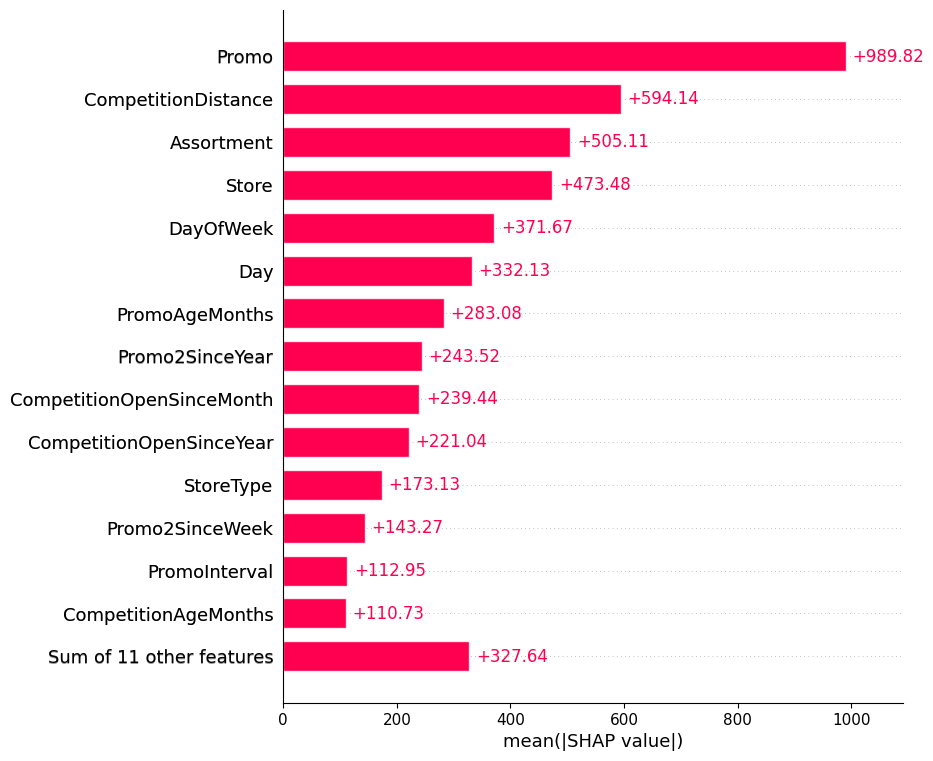

In [17]:
shap.plots.bar(
    shap_values,
    max_display=15
)

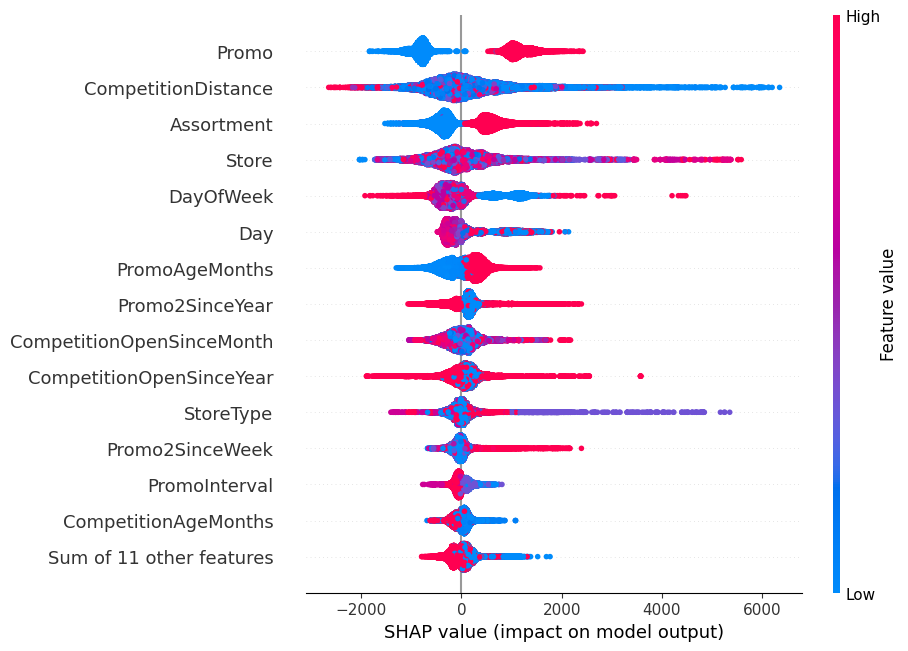

In [18]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

In [19]:
feature_importance = pd.DataFrame({
    "Feature": X_analysis.columns,
    "MeanSHAP": np.abs(shap_values.values).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    "MeanSHAP",
    ascending=False
)

feature_importance.head(10)

,Feature,MeanSHAP
3,Promo,989.822246
8,CompetitionDistance,594.137840
7,Assortment,505.112482
0,Store,473.480396
1,DayOfWeek,371.669066
17,Day,332.132688
24,PromoAgeMonths,283.079857
13,Promo2SinceYear,243.516715
9,CompetitionOpenSinceMonth,239.439902
10,CompetitionOpenSinceYear,221.043124


In [20]:
top_features = feature_importance.head(4)["Feature"].tolist()

top_features

['Promo', 'CompetitionDistance', 'Assortment', 'Store']

Promo


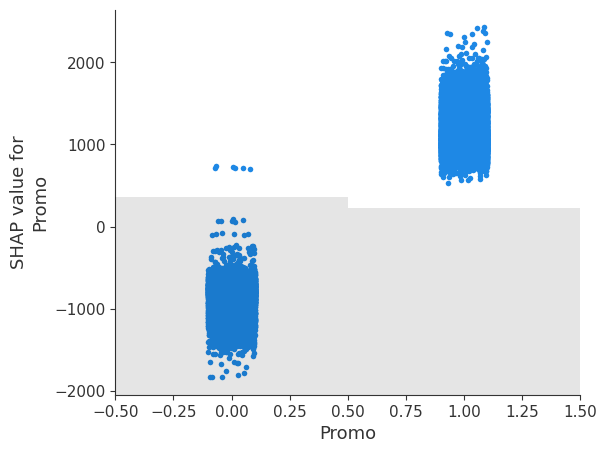

CompetitionDistance


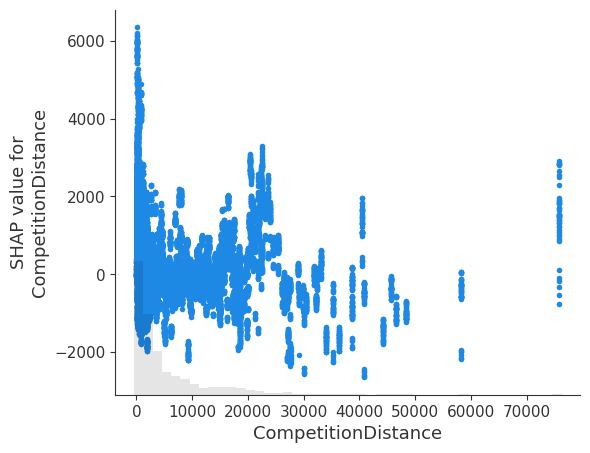

Assortment


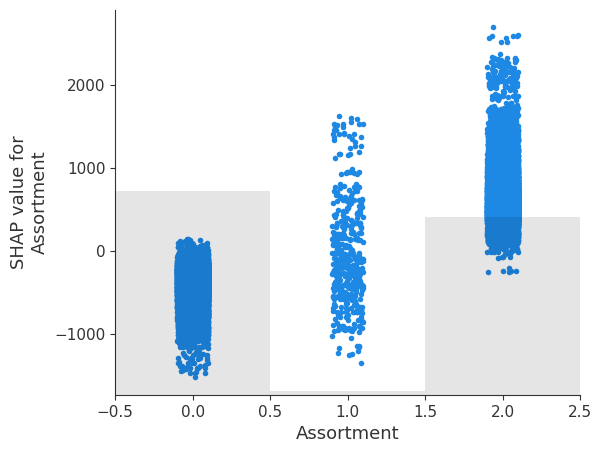

Store


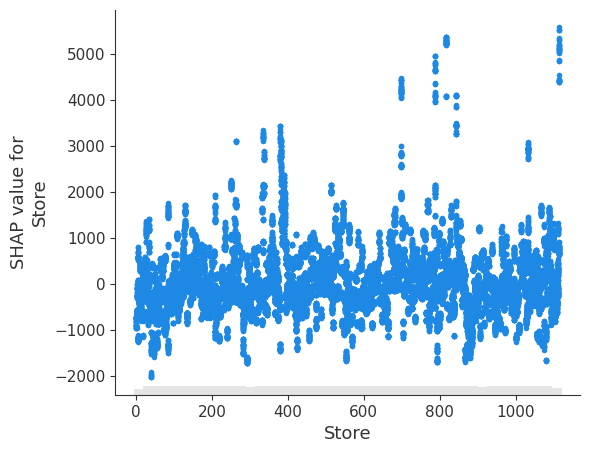

In [21]:
for feature in top_features:

    print("="*60)
    print(feature)

    shap.plots.scatter(
        shap_values[:, feature]
    )

In [22]:
predictions = model.predict(X_analysis)

Predicted Sales: 28604.693


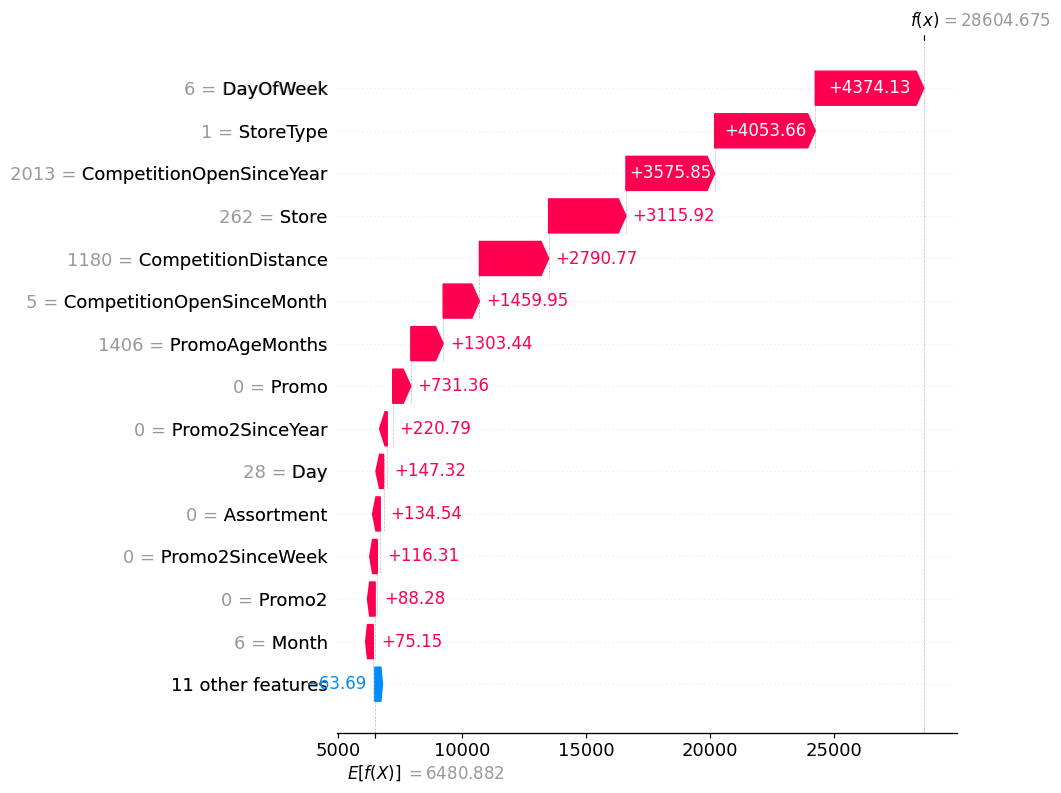

In [ ]:
highest = np.argmax(predictions)

print("Predicted Sales:", predictions[highest])

shap.plots.waterfall(
    shap_values[highest],
    max_display=15
)

Predicted Sales: 217.2218


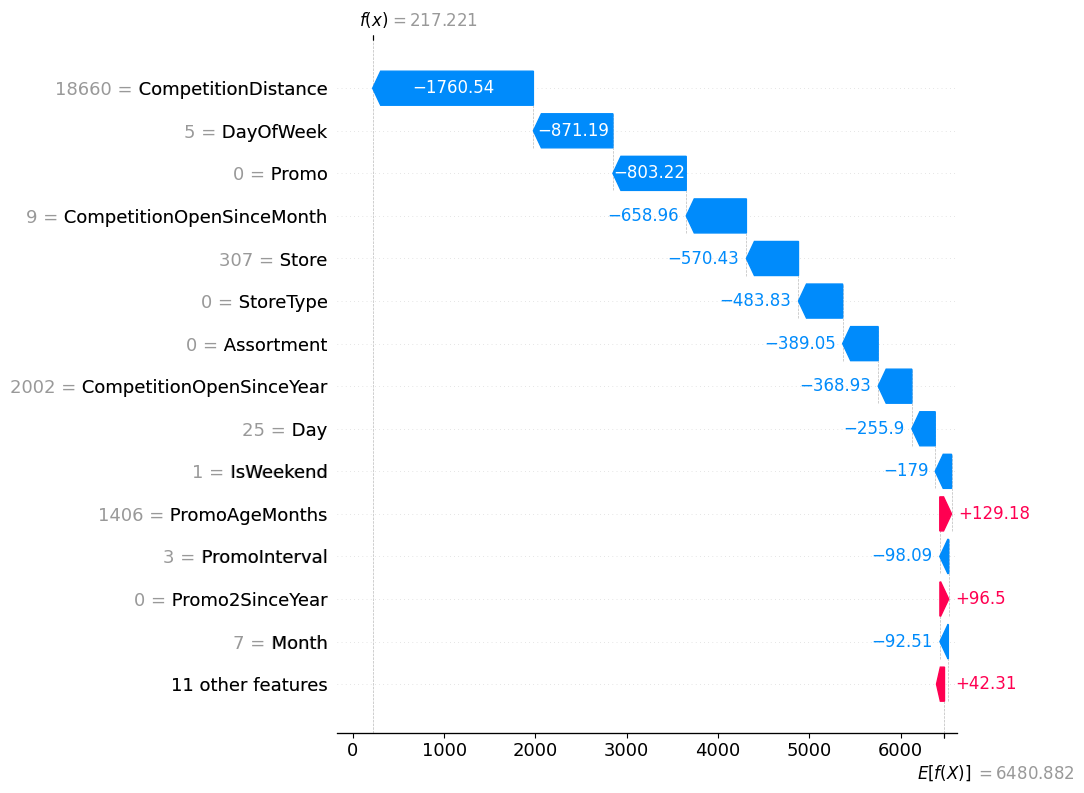

In [24]:
lowest = np.argmin(predictions)

print("Predicted Sales:", predictions[lowest])

shap.plots.waterfall(
    shap_values[lowest],
    max_display=15
)

In [25]:
results = analysis_df.copy()

results["Predicted"] = predictions

results["AbsoluteError"] = np.abs(
    results["Sales"] -
    results["Predicted"]
)

results.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Day,WeekOfYear,Quarter,IsWeekend,IsMonthStart,IsMonthEnd,CompetitionAgeMonths,PromoAgeMonths,Predicted,AbsoluteError
0,1,4,2015-07-31,5263,555,1,1,0,1,2,...,31,31,3,0,0,1,84,1407,6227.339844,964.339844
1,2,4,2015-07-31,6064,625,1,1,0,1,0,...,31,31,3,0,0,1,94,67,7208.651855,1144.651855
2,3,4,2015-07-31,8314,821,1,1,0,1,0,...,31,31,3,0,0,1,105,55,9363.342773,1049.342773
3,4,4,2015-07-31,13995,1498,1,1,0,1,2,...,31,31,3,0,0,1,71,1407,11723.235352,2271.764648
4,5,4,2015-07-31,4822,559,1,1,0,1,0,...,31,31,3,0,0,1,4,1407,6731.965820,1909.965820


In [26]:
largest_errors = results.sort_values(
    "AbsoluteError",
    ascending=False
)

largest_errors[
    [
        "Store",
        "Date",
        "Sales",
        "Predicted",
        "AbsoluteError"
    ]
].head(10)

,Store,Date,Sales,Predicted,AbsoluteError
38929,909,2015-06-22,41551,9504.714844,32046.285156
37815,909,2015-06-23,30038,9049.958008,20988.041992
31594,292,2015-06-29,29161,9166.180664,19994.819336
25459,876,2015-07-06,27330,8830.074219,18499.925781
24345,876,2015-07-07,23927,8227.448242,15699.551758
30479,292,2015-06-30,23584,9175.382812,14408.617188
40075,909,2015-06-20,22882,8799.683594,14082.316406
12068,909,2015-07-20,23081,9627.419922,13453.580078
23231,876,2015-07-08,19665,7945.310547,11719.689453
26606,876,2015-07-04,14708,4186.788574,10521.211426


Actual: 41551
Predicted: 9504.715


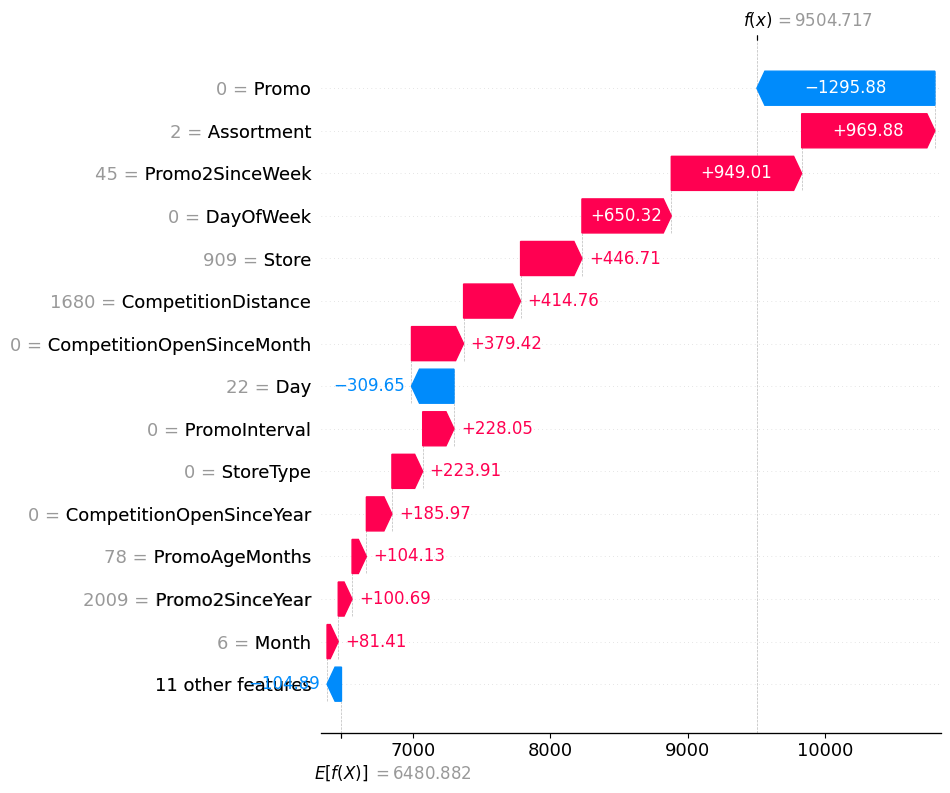

In [27]:
worst_index = largest_errors.index[0]

position = np.where(X_analysis.index == worst_index)[0][0]

print("Actual:", results.loc[worst_index, "Sales"])
print("Predicted:", results.loc[worst_index, "Predicted"])

shap.plots.waterfall(
    shap_values[position],
    max_display=15
)

In [28]:
native_importance = pd.DataFrame({
    "Feature": X_analysis.columns,
    "XGBoost": model.feature_importances_
})

comparison = feature_importance.merge(
    native_importance,
    on="Feature"
)

comparison = comparison.sort_values(
    "MeanSHAP",
    ascending=False
)

comparison.head(15)

,Feature,MeanSHAP,XGBoost
0,Promo,989.822246,0.138925
1,CompetitionDistance,594.137840,0.062907
2,Assortment,505.112482,0.066037
3,Store,473.480396,0.052835
4,DayOfWeek,371.669066,0.034035
5,Day,332.132688,0.037591
6,PromoAgeMonths,283.079857,0.030020
7,Promo2SinceYear,243.516715,0.076343
8,CompetitionOpenSinceMonth,239.439902,0.061455
9,CompetitionOpenSinceYear,221.043124,0.069753


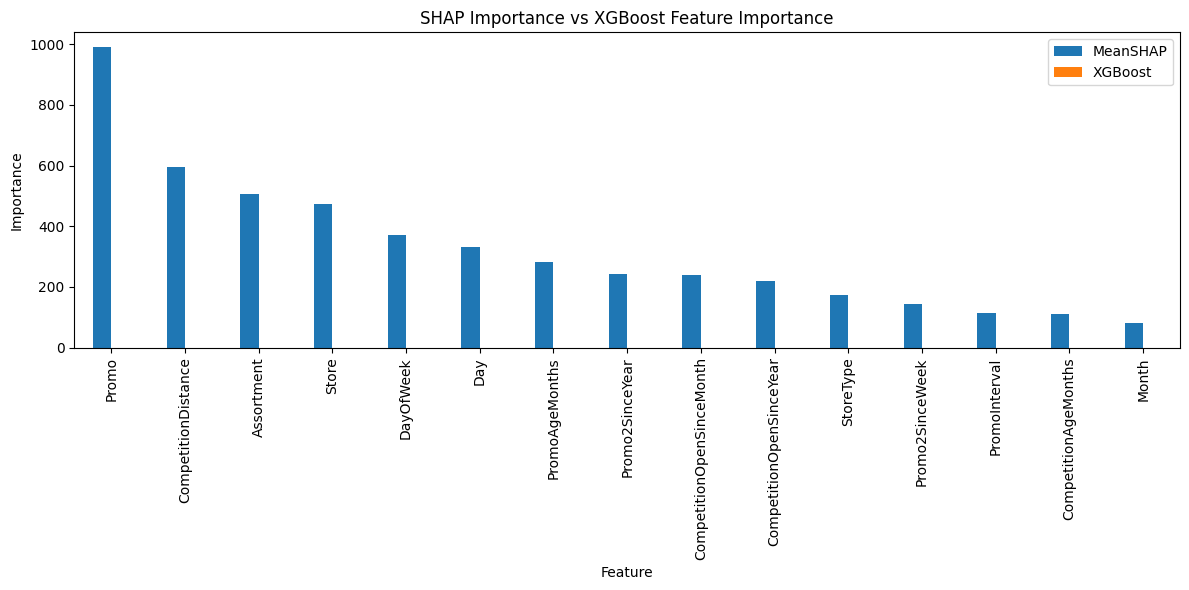

In [29]:
comparison = comparison.set_index("Feature")

comparison.head(15).plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("SHAP Importance vs XGBoost Feature Importance")

plt.ylabel("Importance")

plt.tight_layout()

plt.show()